# Bagian 3: Aturan *Risk Set* Kuantil Kausal, Pelabelan Target, & Skema Walk-Forward

**Cakupan Notebook (Tahap 5, 5B, & 5C):**
- Penurunan ambang *Risk Set* berbasis kuantil kausal pra-evaluasi dari jendela jangkar Fold 1 (`q_idx 2..6`: `P60 roll4 = 4,74%` dan `P65 cummax = 7,94%`).
- Pembentukan label target kemunculan pada horizon $H=2$ kuartal ke depan (`Q+1` / `Q+2`) dan audit bertahap *Risk Set* (`1.270` sampel kandidat).
- Pembentukan 6 fold *Expanding-Window Walk-Forward* dengan *purge/embargo* $H=2$ kuartal bebas *data leakage* (**Gambar 2B**).
- Verifikasi kuantil jangkar Fold 1 dan analisis sensitivitas keketatan target (*Anti-Mean-Reversion* & *Binomial SE Guard*).


## 1. Modul Kuantil Kausal Pra-Evaluasi, Pelabelan Target ($H=2$), & Splitter Walk-Forward


In [1]:
import os
import warnings
from pathlib import Path
from dataclasses import dataclass
from typing import List, Dict, Tuple
import pandas as pd

# Nonaktifkan inferensi ArrowStringArray otomatis pada Pandas >= 2.2 / 3.0
# untuk mencegah ArrowException (ChunkedArray.to_numpy wrapping error) pada teks deskripsi panjang
try:
    pd.options.future.infer_string = False
except Exception:
    pass

warnings.filterwarnings("ignore", message=".*X does not have valid feature names.*")
warnings.filterwarnings("ignore", message=".*IProgress not found.*")

PROJECT_ROOT = Path(os.environ.get("EMERGING_SKILLS_ROOT", Path.cwd()))
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DEFAULT_RAW_CSV = Path(
    os.environ.get(
        "THEIRSTACK_CSV_PATH",
        str(PROJECT_ROOT / "data" / "raw" / "theirstack_pure_combined_2021_2026.csv"),
    )
)
if not DEFAULT_RAW_CSV.exists():
    DEFAULT_RAW_CSV = PROJECT_ROOT / "data" / "raw" / "theirstack_pure_combined_2021_2026.csv"

@dataclass
class PipelineConfig:
    """Konfigurasi terpusat dan reproducible untuk seluruh tahap pipeline."""

    # 1. Paths
    project_root: Path = PROJECT_ROOT
    raw_data_path: Path = DEFAULT_RAW_CSV
    processed_dir: Path = PROJECT_ROOT / "data" / "processed"
    outputs_dir: Path = PROJECT_ROOT / "outputs"
    audit_dir: Path = PROJECT_ROOT / "outputs" / "audit"
    features_dir: Path = PROJECT_ROOT / "outputs" / "features"
    predictions_dir: Path = PROJECT_ROOT / "outputs" / "predictions"
    metrics_dir: Path = PROJECT_ROOT / "outputs" / "metrics"
    lead_time_dir: Path = PROJECT_ROOT / "outputs" / "lead_time"
    figures_dir: Path = PROJECT_ROOT / "outputs" / "figures"
    models_dir: Path = PROJECT_ROOT / "models"

    # 2. Preprocessing & Filtering Parameters
    deduplicate_within_quarter: bool = True
    require_it_relevance: bool = True
    use_raw_extracted_skills_fallback_when_desc_empty: bool = True

    # 3. Temporal & Panel Parameters
    min_quarter_postings_for_complete: int = 150
    max_postings_per_company_quarter: int = 5
    min_total_skill_mentions: int = 5
    min_history_quarters: int = 2
    epsilon_share: float = 0.002

    # 4. Co-occurrence Network Parameters (M2: Context Evolution)
    min_cooccurrence_count: int = 2
    jaccard_edge_threshold: float = 0.01

    # 5. Primary Target Future Emergence Definition:
    #    Causal Pre-Evaluation Quantile-Anchored Risk Set + Anti-Mean-Reversion + Binomial SE Guard (H = 2 Quarters)
    horizon_quarters: int = 2
    target_mode: str = "causal_quantile_anchored_optimal_with_multi_regime_se_audit"
    restrict_to_risk_set: bool = True
    use_quantile_anchored_primary_rule: bool = True
    anchor_max_quarter_idx: int = 6  # = first_eval_quarter_idx (9) - H (2) - 1 -> Fold 1 Train Window (2021-Q3..2022-Q3)

    # Parameter Kuantil Kausal Utama (ditetapkan pada jendela jangkar pra-evaluasi q_idx 2..6):
    risk_set_roll4_quantile: float = 0.60      # P60(causal_roll4_share) pada jendela jangkar pra-evaluasi
    risk_set_cummax_quantile: float = 0.65     # P65(causal_cummax_share) pada jendela jangkar pra-evaluasi
    emergence_abs_gain_quantile: float = 0.65  # P65(abs_gain_ref) kandidat pada jendela jangkar pra-evaluasi
    emergence_rel_gain_quantile: float = 0.65  # P65(rel_gain_ref) kandidat pada jendela jangkar pra-evaluasi

    # Parameter Ketahanan Fluktuasi Permintaan & Daya Pisah Tingkat Skill:
    use_anti_mean_reversion_baseline: bool = False  # False pada Rezim Optimal Utama; True pada Rezim Audit Ketat SE (Tahap 5C & 6B)
    min_se_guard_multiplier: float = 0.0            # 0.0 pada Rezim Optimal Utama; diuji bertahap 0.5x, 1.0x, 1.5x, 2.0x SE (Bukti Yazdanian et al., 2022)
    require_sustained_horizon_mean: bool = False    # False pada Rezim Optimal Utama; True pada Rezim Audit Ketat SE (Tahap 5C & 6B)
    se_guard_audit_levels: Tuple[float, ...] = (0.5, 1.0, 1.5, 2.0)

    # Ambang numerik hasil proyeksi kuantil jangkar pra-evaluasi (diperbarui otomatis dari data oleh
    # fit_causal_quantile_thresholds_from_anchor() pada Tahap 5; bukan lagi angka tetap 5,0% / 7,5%):
    max_baseline_share: float = 0.04737
    max_career_cummax_share: float = 0.07938
    min_future_job_count: int = 3
    min_future_abs_share_gain: float = 0.0035
    min_future_rel_share_gain: float = 0.25
    min_future_cooc_degree: float = 0.0
    min_future_role_entropy: float = 0.0

    # 6. Walk-Forward Validation Parameters (Section 10)
    first_eval_quarter_idx: int = 9
    test_window_size: int = 2
    validation_folds_count: int = 4
    top_k_values: Tuple[int, ...] = (5, 10, 15)

    # 7. Parameter Early Warning & Lead Time (Terikat Ketat pada Horizon H=2 Kuartal)
    confirmation_consecutive_quarters: int = 1
    default_prob_threshold: float = 0.50

    # 8. Reproducibility & ML Hyperparameters (Section 11)
    random_seed: int = 42
    allow_numpy_scipy_fallback: bool = True

    def ensure_dirs(self) -> None:
        for d in [
            self.processed_dir,
            self.outputs_dir,
            self.audit_dir,
            self.features_dir,
            self.predictions_dir,
            self.metrics_dir,
            self.lead_time_dir,
            self.figures_dir,
            self.models_dir,
        ]:
            d.mkdir(parents=True, exist_ok=True)

# Definisi Kelompok Fitur untuk Studi Ablasi (4 Fitur Inti Multi-Indikator pada Risk Set Kandidat Identik)
DEMAND_FEATURES: List[str] = [
    "qoq_growth_smoothed",
    "ema_ratio_short_long",
]

CONTEXT_FEATURES: List[str] = [
    "cooc_weighted_degree_roll4",
]

CONTEXT_SYNERGY_FEATURES: List[str] = []

ROLE_FEATURES: List[str] = [
    "role_entropy_roll4",
]

MATURITY_FEATURES: List[str] = []

ABLATION_FEATURE_SETS: Dict[str, List[str]] = {
    "M1_Demand_Only": DEMAND_FEATURES,
    "M2_Context_Only": CONTEXT_FEATURES,
    "M3_Demand_Context": DEMAND_FEATURES + CONTEXT_FEATURES + CONTEXT_SYNERGY_FEATURES,
    "M4_Demand_Context_Role": DEMAND_FEATURES + CONTEXT_FEATURES + CONTEXT_SYNERGY_FEATURES + ROLE_FEATURES,
    "M5_Full_Multi_Signal": DEMAND_FEATURES + CONTEXT_FEATURES + CONTEXT_SYNERGY_FEATURES + ROLE_FEATURES + MATURITY_FEATURES,
}
import matplotlib.pyplot as plt
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

# Otomatis cari lokasi berkas CSV TheirStack jika dijalankan di direktori lokal (mis. folder scraping/ atau project root)
import pickle
import matplotlib.pyplot as plt
cfg = PipelineConfig()
cfg.ensure_dirs()
_s2_path = cfg.outputs_dir / "demo_state" / "stage02_state.pkl"
if "feat_df" not in globals() and _s2_path.exists():
    with open(_s2_path, "rb") as _f:
        _s2 = pickle.load(_f)
    panel_df = _s2["panel_df"]
    feat_df = _s2["feat_df"]
    edges_history_df = _s2["edges_history_df"]
    audit_tables = _s2.get("audit_tables", {})

from typing import Dict, List, Optional, Tuple, Any
import pandas as pd
import numpy as np

def compute_future_horizon_outcomes(
    panel_df: pd.DataFrame,
    horizon_quarters: int = 2,
    epsilon_share: float = 0.002,
) -> pd.DataFrame:
    """
    Menghitung capaian permintaan masa depan pada {t+1, ..., t+H} untuk setiap (skill, quarter_idx),
    mencakup gain baseline 1Q, gain baseline Rolling-4Q, gain referensi Anti-Mean-Reversion
    (`baseline_ref_share = max(skill_share, causal_roll4_share)`), dan Binomial SE selisih pangsa.
    """
    df = panel_df.sort_values(["skill", "quarter_idx"]).copy()
    g = df.groupby("skill", group_keys=False)

    roll4 = g["skill_share"].transform(lambda s: s.rolling(window=4, min_periods=1).mean())
    df["causal_roll4_share"] = roll4
    df["causal_cummax_share"] = g["skill_share"].cummax()
    # Baseline referensi anti-mean-reversion: menolak pantulan semu dari kuartal tunggal yang sedang turun
    df["baseline_ref_share"] = np.maximum(df["skill_share"], df["causal_roll4_share"])

    if "total_jobs_quarter" in df.columns:
        n_t_series = df["total_jobs_quarter"].astype(float)
    else:
        ratio = (df["job_count"] / df["skill_share"]).replace([np.inf, -np.inf], np.nan)
        n_q_map = ratio.groupby(df["quarter_idx"]).median()
        n_t_series = df["quarter_idx"].map(n_q_map).fillna(400.0).astype(float)
    df["_n_t_effective"] = np.maximum(n_t_series, 1.0)

    lead_shares = []
    lead_counts = []
    for h in range(1, horizon_quarters + 1):
        s_h = g["skill_share"].shift(-h)
        c_h = g["job_count"].shift(-h)
        n_h = g["_n_t_effective"].shift(-h).fillna(df["_n_t_effective"])
        df[f"future_share_t_plus_{h}"] = s_h
        df[f"future_count_t_plus_{h}"] = c_h
        df[f"future_total_jobs_t_plus_{h}"] = n_h

        # 1. Gain terhadap 1 kuartal tunggal (legacy 1Q baseline)
        df[f"future_abs_gain_1q_t_plus_{h}"] = s_h - df["skill_share"]
        df[f"future_rel_gain_1q_t_plus_{h}"] = (s_h - df["skill_share"]) / (df["skill_share"] + epsilon_share)

        # 2. Gain terhadap rata-rata bergerak 4 kuartal (causal_roll4_share)
        df[f"future_abs_gain_roll4_t_plus_{h}"] = s_h - df["causal_roll4_share"]
        df[f"future_rel_gain_roll4_t_plus_{h}"] = (s_h - df["causal_roll4_share"]) / (df["causal_roll4_share"] + epsilon_share)

        # 3. Gain terhadap baseline referensi anti-mean-reversion: max(skill_share_t, causal_roll4_share_t)
        df[f"future_abs_gain_ref_t_plus_{h}"] = s_h - df["baseline_ref_share"]
        df[f"future_rel_gain_ref_t_plus_{h}"] = (s_h - df["baseline_ref_share"]) / (df["baseline_ref_share"] + epsilon_share)

        # Default kolom gain menunjuk pada gain berbasis baseline_ref_share (dan tetap kompatibel bila 1Q diminta)
        df[f"future_abs_gain_t_plus_{h}"] = df[f"future_abs_gain_1q_t_plus_{h}"]
        df[f"future_rel_gain_t_plus_{h}"] = df[f"future_rel_gain_1q_t_plus_{h}"]

        # 4. Galat baku sampling binomial untuk selisih dua proporsi antara kuartal t dan t+h
        p_bar_h = np.clip(0.5 * (df["baseline_ref_share"] + s_h), 1e-5, 1.0 - 1e-5)
        df[f"future_se_diff_t_plus_{h}"] = np.sqrt(
            p_bar_h * (1.0 - p_bar_h) * (1.0 / df["_n_t_effective"] + 1.0 / np.maximum(n_h, 1.0))
        )

        lead_shares.append(f"future_share_t_plus_{h}")
        lead_counts.append(f"future_count_t_plus_{h}")

        if "cooc_degree_norm" in df.columns:
            df[f"future_cooc_deg_t_plus_{h}"] = g["cooc_degree_norm"].shift(-h)
        else:
            df[f"future_cooc_deg_t_plus_{h}"] = 1.0

        if "role_shannon_entropy" in df.columns:
            df[f"future_role_ent_t_plus_{h}"] = g["role_shannon_entropy"].shift(-h)
        else:
            df[f"future_role_ent_t_plus_{h}"] = 1.0

    df = df.drop(columns=["_n_t_effective"])
    df["has_complete_future_horizon"] = df[lead_shares].notna().all(axis=1)
    df["future_peak_share"] = df[lead_shares].max(axis=1)
    df["future_mean_share"] = df[lead_shares].mean(axis=1)
    df["future_peak_count"] = df[lead_counts].max(axis=1)
    df["future_sum_count"] = df[lead_counts].sum(axis=1)

    if "cooc_degree_norm" in df.columns:
        deg_leads = [df[f"future_cooc_deg_t_plus_{h}"] for h in range(1, horizon_quarters + 1)]
        df["future_peak_cooc_deg"] = pd.concat(deg_leads, axis=1).max(axis=1)
    else:
        df["future_peak_cooc_deg"] = 1.0

    if "role_shannon_entropy" in df.columns:
        role_leads = [df[f"future_role_ent_t_plus_{h}"] for h in range(1, horizon_quarters + 1)]
        df["future_peak_role_ent"] = pd.concat(role_leads, axis=1).max(axis=1)
    else:
        df["future_peak_role_ent"] = 1.0

    if horizon_quarters >= 2:
        df["peak_share_quarter_offset"] = np.where(
            ~df["has_complete_future_horizon"],
            np.nan,
            np.where(
                df["future_share_t_plus_1"] >= df["future_share_t_plus_2"], 1.0, 2.0
            ),
        )
    else:
        df["peak_share_quarter_offset"] = np.where(df["has_complete_future_horizon"], 1.0, np.nan)

    df["emergence_quarter_offset"] = df["peak_share_quarter_offset"]
    df["future_abs_share_gain"] = df["future_peak_share"] - df["skill_share"]
    df["future_rel_share_gain"] = (df["future_peak_share"] - df["skill_share"]) / (
        df["skill_share"] + epsilon_share
    )
    df["future_abs_share_gain_ref"] = df["future_peak_share"] - df["baseline_ref_share"]
    df["future_rel_share_gain_ref"] = (df["future_peak_share"] - df["baseline_ref_share"]) / (
        df["baseline_ref_share"] + epsilon_share
    )
    return df

def fit_causal_quantile_thresholds_from_anchor(
    df_with_outcomes: pd.DataFrame,
    cfg: Any,
    update_cfg_in_place: bool = True,
) -> Dict[str, Any]:
    """
    Tetapkan ambang Risk Set (`max_baseline_share`, `max_career_cummax_share`) dan ambang lonjakan
    (`min_future_abs_share_gain`, `min_future_rel_share_gain`) secara langsung dari distribusi kuantil
    jendela jangkar pra-evaluasi (`q_idx in [min_history_quarters, anchor_max_quarter_idx]`, identik dengan
    data latih Fold 1) sehingga aturan kuantil benar-benar menjadi KONFIGURASI UTAMA (Primary Rule).
    """
    H = int(getattr(cfg, "horizon_quarters", 2))
    min_q = int(getattr(cfg, "min_history_quarters", 2))
    anchor_max_q = int(getattr(cfg, "anchor_max_quarter_idx", getattr(cfg, "first_eval_quarter_idx", 9) - H - 1))
    q_roll4_lvl = float(getattr(cfg, "risk_set_roll4_quantile", 0.60))
    q_cummax_lvl = float(getattr(cfg, "risk_set_cummax_quantile", 0.65))
    q_abs_lvl = float(getattr(cfg, "emergence_abs_gain_quantile", 0.65))
    q_rel_lvl = float(getattr(cfg, "emergence_rel_gain_quantile", 0.65))
    use_ref = bool(getattr(cfg, "use_anti_mean_reversion_baseline", True))

    anchor_sub = df_with_outcomes[
        (df_with_outcomes["quarter_idx"] >= min_q)
        & (df_with_outcomes["quarter_idx"] <= anchor_max_q)
    ].copy()
    if len(anchor_sub) == 0:
        anchor_sub = df_with_outcomes[df_with_outcomes["quarter_idx"] >= min_q].copy()

    roll4_cutoff = float(anchor_sub["causal_roll4_share"].quantile(q_roll4_lvl)) if len(anchor_sub) > 0 else 0.04737
    cummax_cutoff = float(anchor_sub["causal_cummax_share"].quantile(q_cummax_lvl)) if len(anchor_sub) > 0 else 0.07938

    cand_anchor = anchor_sub[
        (anchor_sub["causal_roll4_share"] <= roll4_cutoff)
        & (anchor_sub["causal_cummax_share"] <= cummax_cutoff)
        & (anchor_sub["has_complete_future_horizon"] == True)
    ].copy()

    if len(cand_anchor) > 0:
        abs_cols_1q = [f"future_abs_gain_1q_t_plus_{h}" if f"future_abs_gain_1q_t_plus_{h}" in cand_anchor.columns else f"future_abs_gain_t_plus_{h}" for h in range(1, H + 1)]
        rel_cols_1q = [f"future_rel_gain_1q_t_plus_{h}" if f"future_rel_gain_1q_t_plus_{h}" in cand_anchor.columns else f"future_rel_gain_t_plus_{h}" for h in range(1, H + 1)]
        best_abs_1q = cand_anchor[abs_cols_1q].max(axis=1)
        best_rel_1q = cand_anchor[rel_cols_1q].max(axis=1)

        if use_ref and f"future_abs_gain_ref_t_plus_1" in cand_anchor.columns:
            abs_cols_ref = [f"future_abs_gain_ref_t_plus_{h}" for h in range(1, H + 1)]
            rel_cols_ref = [f"future_rel_gain_ref_t_plus_{h}" for h in range(1, H + 1)]
            best_abs_ref = cand_anchor[abs_cols_ref].max(axis=1)
            best_rel_ref = cand_anchor[rel_cols_ref].max(axis=1)
            abs_cutoff = float(np.clip(best_abs_ref.quantile(q_abs_lvl), 0.0025, 0.0150))
            rel_cutoff = float(np.clip(best_rel_ref.quantile(q_rel_lvl), 0.20, 1.00))
        else:
            abs_cutoff = float(np.clip(best_abs_1q.quantile(q_abs_lvl), 0.0025, 0.0150))
            rel_cutoff = float(np.clip(best_rel_1q.quantile(q_rel_lvl), 0.20, 1.00))
    else:
        abs_cutoff = 0.0035
        rel_cutoff = 0.25

    if not use_ref:
        # Pada Rezim Utama Kuantil Kausal Optimal, pertahankan syarat lonjakan kuartal individual (+0,35% abs & +25% rel)
        # di dalam Risk Set Kuantil Kausal (P60 = 4,74% & P65 = 7,94%) agar tidak menyensor skill yang sedang tumbuh bertahap
        abs_cutoff_operational = 0.0035
        rel_cutoff_operational = 0.25
    else:
        abs_cutoff_operational = abs_cutoff
        rel_cutoff_operational = rel_cutoff

    if update_cfg_in_place and cfg is not None:
        cfg.max_baseline_share = round(roll4_cutoff, 6)
        cfg.max_career_cummax_share = round(cummax_cutoff, 6)
        cfg.min_future_abs_share_gain = round(abs_cutoff_operational, 6)
        cfg.min_future_rel_share_gain = round(rel_cutoff_operational, 6)

    return {
        "anchor_min_q_idx": min_q,
        "anchor_max_q_idx": anchor_max_q,
        "n_anchor_total": len(anchor_sub),
        "n_anchor_candidates": len(cand_anchor),
        "risk_set_roll4_quantile": q_roll4_lvl,
        "risk_set_cummax_quantile": q_cummax_lvl,
        "emergence_abs_gain_quantile": q_abs_lvl,
        "emergence_rel_gain_quantile": q_rel_lvl,
        "derived_max_baseline_share": round(roll4_cutoff, 6),
        "derived_max_career_cummax_share": round(cummax_cutoff, 6),
        "derived_min_future_abs_share_gain": round(abs_cutoff_operational, 6),
        "derived_min_future_rel_share_gain": round(rel_cutoff_operational, 6),
        "anchor_p65_abs_gain_raw": round(abs_cutoff, 6),
        "anchor_p65_rel_gain_raw": round(rel_cutoff, 6),
    }

def assign_emergence_labels_with_reasons(
    df_with_outcomes: pd.DataFrame,
    max_baseline_share: float = 0.04737,
    max_career_cummax_share: Optional[float] = 0.07938,
    min_future_job_count: int = 3,
    min_future_abs_share_gain: float = 0.0035,
    min_future_rel_share_gain: float = 0.25,
    min_history_quarters: int = 2,
    min_future_cooc_degree: float = 0.0,
    min_future_role_entropy: float = 0.0,
    restrict_to_risk_set: bool = True,
    use_anti_mean_reversion_baseline: bool = False,
    min_se_guard_multiplier: float = 0.0,
    require_sustained_horizon_mean: bool = False,
) -> pd.DataFrame:
    """
    Menetapkan label biner `target_emerging` (1.0, 0.0, atau NaN) menggunakan:
    1. Penyaringan Risk Set berbasis kuantil kausal (`in_risk_set`):
       `quarter_idx >= min_history_quarters`, `causal_roll4_share <= max_baseline_share` (P60_anchor),
       dan `causal_cummax_share <= max_career_cummax_share` (P65_anchor).
    2. Kualifikasi anti-fluktuasi & anti-saturasi per kuartal (`qualifies_at_t_plus_1` / `qualifies_at_t_plus_2`):
       - Saat `use_anti_mean_reversion_baseline=True`, kenaikan pada t+h diukur terhadap
         `baseline_ref_share = max(skill_share_t, causal_roll4_share_t)`, menyingkirkan pantulan penurunan 1 kuartal.
       - Saat `min_se_guard_multiplier > 0`, `abs_gain_h` juga harus melebihi `min_se_guard_multiplier * SE_diff(t, t+h)`.
       - Saat `require_sustained_horizon_mean=True`, rata-rata pangsa 2 kuartal ke depan harus melampaui `baseline_ref_share`.
    3. Turut menghitung `target_emerging_legacy_fixed` (ambang tetap 5%/7.5%, baseline 1Q, tanpa SE guard) untuk perbandingan audit langsung.
    """
    df = df_with_outcomes.copy()
    if max_career_cummax_share is None:
        max_career_cummax_share = min(1.0, max_baseline_share * 1.5)

    in_risk_set_list = []
    labels = []
    labels_unconditional = []
    labels_multidim = []
    labels_legacy_fixed = []
    reasons = []
    first_offsets = []
    qual_t1_list = []
    qual_t2_list = []

    for row in df.itertuples(index=False):
        q_idx = int(row.quarter_idx)
        has_fut = bool(row.has_complete_future_horizon)
        cur_share = float(row.skill_share)
        roll4_share = float(getattr(row, "causal_roll4_share", cur_share))
        cummax_share = float(getattr(row, "causal_cummax_share", roll4_share))
        base_ref = max(cur_share, roll4_share) if use_anti_mean_reversion_baseline else cur_share

        # Primary Causal Risk Set eligibility at quarter t (driven by P60/P65 pre-evaluation quantiles)
        c1_in_risk_set = (
            (q_idx >= min_history_quarters)
            and (roll4_share <= max_baseline_share)
            and (cummax_share <= max_career_cummax_share)
        )
        # Pengecekan Risk Set legacy tetap 5,0% / 7,5% untuk perbandingan audit
        c1_legacy = (
            (q_idx >= min_history_quarters)
            and (roll4_share <= 0.05)
            and (cummax_share <= 0.075)
        )
        in_risk_set_list.append(bool(c1_in_risk_set))

        if q_idx < min_history_quarters:
            labels.append(np.nan)
            labels_unconditional.append(np.nan)
            labels_multidim.append(np.nan)
            labels_legacy_fixed.append(np.nan)
            first_offsets.append(np.nan)
            qual_t1_list.append(False)
            qual_t2_list.append(False)
            reasons.append(
                f"EXCLUDED_INITIAL_WARMUP: quarter_idx={q_idx} < min_history_quarters={min_history_quarters}"
            )
            continue

        if not has_fut:
            labels.append(np.nan)
            labels_unconditional.append(np.nan)
            labels_multidim.append(np.nan)
            labels_legacy_fixed.append(np.nan)
            first_offsets.append(np.nan)
            qual_t1_list.append(False)
            qual_t2_list.append(False)
            reasons.append(
                "EXCLUDED_RIGHT_CENSORED: Kuartal masa depan t+1..t+H belum lengkap pada akhir observasi"
            )
            continue

        fut_cnt = float(row.future_peak_count) if pd.notna(row.future_peak_count) else 0.0
        fut_sum = float(getattr(row, "future_sum_count", fut_cnt * 2)) if pd.notna(getattr(row, "future_sum_count", np.nan)) else fut_cnt * 2
        fut_mean = float(getattr(row, "future_mean_share", cur_share)) if pd.notna(getattr(row, "future_mean_share", np.nan)) else cur_share

        c_t1 = float(getattr(row, "future_count_t_plus_1", fut_cnt))
        c_t2 = float(getattr(row, "future_count_t_plus_2", fut_cnt))

        abs_1q_t1 = float(getattr(row, "future_abs_gain_1q_t_plus_1", getattr(row, "future_abs_gain_t_plus_1", 0.0)))
        rel_1q_t1 = float(getattr(row, "future_rel_gain_1q_t_plus_1", getattr(row, "future_rel_gain_t_plus_1", 0.0)))
        abs_1q_t2 = float(getattr(row, "future_abs_gain_1q_t_plus_2", getattr(row, "future_abs_gain_t_plus_2", 0.0)))
        rel_1q_t2 = float(getattr(row, "future_rel_gain_1q_t_plus_2", getattr(row, "future_rel_gain_t_plus_2", 0.0)))

        if use_anti_mean_reversion_baseline:
            abs_t1 = float(getattr(row, "future_abs_gain_ref_t_plus_1", abs_1q_t1))
            rel_t1 = float(getattr(row, "future_rel_gain_ref_t_plus_1", rel_1q_t1))
            abs_t2 = float(getattr(row, "future_abs_gain_ref_t_plus_2", abs_1q_t2))
            rel_t2 = float(getattr(row, "future_rel_gain_ref_t_plus_2", rel_1q_t2))
        else:
            abs_t1, rel_t1 = abs_1q_t1, rel_1q_t1
            abs_t2, rel_t2 = abs_1q_t2, rel_1q_t2

        se_t1 = float(getattr(row, "future_se_diff_t_plus_1", 0.0))
        se_t2 = float(getattr(row, "future_se_diff_t_plus_2", 0.0))
        se_ok_t1 = (abs_t1 >= min_se_guard_multiplier * se_t1) if min_se_guard_multiplier > 0.0 else True
        se_ok_t2 = (abs_t2 >= min_se_guard_multiplier * se_t2) if min_se_guard_multiplier > 0.0 else True

        sustained_ok = (fut_mean > base_ref) if require_sustained_horizon_mean else True

        deg_t1 = float(getattr(row, "future_cooc_deg_t_plus_1", 1.0))
        role_t1 = float(getattr(row, "future_role_ent_t_plus_1", 1.0))
        deg_t2 = float(getattr(row, "future_cooc_deg_t_plus_2", 1.0))
        role_t2 = float(getattr(row, "future_role_ent_t_plus_2", 1.0))

        c2_horizon_sum = fut_sum >= (min_future_job_count + 2)

        # Kualifikasi legacy tetap 1Q (untuk perbandingan audit berdampingan)
        qual_leg_t1 = c1_legacy and c2_horizon_sum and (c_t1 >= 3) and (abs_1q_t1 >= 0.0035) and (rel_1q_t1 >= 0.25)
        qual_leg_t2 = c1_legacy and c2_horizon_sum and (c_t2 >= 3) and (abs_1q_t2 >= 0.0035) and (rel_1q_t2 >= 0.25)
        labels_legacy_fixed.append(np.nan if not c1_legacy else (1.0 if (qual_leg_t1 or qual_leg_t2) else 0.0))

        # Kualifikasi individual ketat per kuartal pada Q+1 dan Q+2 sesuai aturan Kuantil Utama + Anti-Fluktuasi
        qual_t1 = (
            c1_in_risk_set
            and c2_horizon_sum
            and sustained_ok
            and (c_t1 >= min_future_job_count)
            and (abs_t1 >= min_future_abs_share_gain)
            and (rel_t1 >= min_future_rel_share_gain)
            and se_ok_t1
            and (deg_t1 >= min_future_cooc_degree)
            and (role_t1 >= min_future_role_entropy)
        )
        qual_t2 = (
            c1_in_risk_set
            and c2_horizon_sum
            and sustained_ok
            and (c_t2 >= min_future_job_count)
            and (abs_t2 >= min_future_abs_share_gain)
            and (rel_t2 >= min_future_rel_share_gain)
            and se_ok_t2
            and (deg_t2 >= min_future_cooc_degree)
            and (role_t2 >= min_future_role_entropy)
        )
        qual_t1_list.append(bool(qual_t1))
        qual_t2_list.append(bool(qual_t2))

        qual_t1_md = qual_t1 and (deg_t1 >= 0.08) and (role_t1 >= 0.15)
        qual_t2_md = qual_t2 and (deg_t2 >= 0.08) and (role_t2 >= 0.15)

        if not c1_in_risk_set:
            labels_unconditional.append(0.0)
            labels_multidim.append(np.nan if restrict_to_risk_set else 0.0)
            first_offsets.append(np.nan)
            if restrict_to_risk_set:
                labels.append(np.nan)
                reasons.append(
                    f"EXCLUDED_OUTSIDE_RISK_SET: Already_Mainstream_Established(roll4={roll4_share*100:.2f}%>{max_baseline_share*100:.2f}%_or_cummax={cummax_share*100:.2f}%>{max_career_cummax_share*100:.2f}%)"
                )
            else:
                labels.append(0.0)
                reasons.append(
                    f"NEGATIVE: Already_Mainstream_Established(roll4={roll4_share*100:.2f}%>{max_baseline_share*100:.2f}%_or_cummax={cummax_share*100:.2f}%>{max_career_cummax_share*100:.2f}%)"
                )
            continue

        labels_multidim.append(1.0 if (qual_t1_md or qual_t2_md) else 0.0)

        if qual_t1 or qual_t2:
            labels.append(1.0)
            labels_unconditional.append(1.0)
            first_off = 1.0 if qual_t1 else 2.0
            first_offsets.append(first_off)
            q_cnt_hit = int(c_t1) if qual_t1 else int(c_t2)
            q_abs_hit = abs_t1 if qual_t1 else abs_t2
            q_rel_hit = rel_t1 if qual_t1 else rel_t2
            q_se_hit = se_t1 if qual_t1 else se_t2
            reasons.append(
                f"POSITIVE_EMERGENCE(first_offset=+{int(first_off)}Q): base_ref={base_ref*100:.2f}% "
                f"(roll4={roll4_share*100:.2f}%<={max_baseline_share*100:.2f}%, cummax={cummax_share*100:.2f}%<={max_career_cummax_share*100:.2f}%), "
                f"Q+{int(first_off)}_count={q_cnt_hit} (>={min_future_job_count}, sum_2Q={int(fut_sum)}), "
                f"Q+{int(first_off)}_abs_gain_ref=+{q_abs_hit*100:.2f}% (>=+{min_future_abs_share_gain*100:.2f}% & >={min_se_guard_multiplier:.1f}xSE={q_se_hit*100:.2f}%), "
                f"Q+{int(first_off)}_rel_gain_ref=+{q_rel_hit*100:.1f}% (>=+{min_future_rel_share_gain*100:.0f}%)"
            )
        else:
            labels.append(0.0)
            labels_unconditional.append(0.0)
            first_offsets.append(np.nan)
            max_abs_ref = max(abs_t1, abs_t2)
            max_rel_ref = max(rel_t1, rel_t2)
            failed = []
            joint_basic_t1 = c2_horizon_sum and (c_t1 >= min_future_job_count) and (abs_t1 >= min_future_abs_share_gain) and (rel_t1 >= min_future_rel_share_gain)
            joint_basic_t2 = c2_horizon_sum and (c_t2 >= min_future_job_count) and (abs_t2 >= min_future_abs_share_gain) and (rel_t2 >= min_future_rel_share_gain)
            if not ((c_t1 >= min_future_job_count or c_t2 >= min_future_job_count) and c2_horizon_sum):
                failed.append(f"Low_Future_Support(c_t1={int(c_t1)},c_t2={int(c_t2)},sum={int(fut_sum)})")
            if not (abs_t1 >= min_future_abs_share_gain or abs_t2 >= min_future_abs_share_gain):
                failed.append(f"Insufficient_Abs_Gain_Above_Ref(max={max_abs_ref*100:+.2f}%<+{min_future_abs_share_gain*100:.2f}%)")
            if not (rel_t1 >= min_future_rel_share_gain or rel_t2 >= min_future_rel_share_gain):
                failed.append(f"Insufficient_Rel_Surge_Above_Ref(max={max_rel_ref*100:+.1f}%<+{min_future_rel_share_gain*100:.0f}%)")
            if not failed and not (joint_basic_t1 or joint_basic_t2):
                failed.append(
                    f"No_Single_Quarter_Jointly_Qualifies(Q+1:[cnt={int(c_t1)},abs={abs_t1*100:+.2f}%,rel={rel_t1*100:+.1f}%], "
                    f"Q+2:[cnt={int(c_t2)},abs={abs_t2*100:+.2f}%,rel={rel_t2*100:+.1f}%])"
                )
            if (joint_basic_t1 and not se_ok_t1) or (joint_basic_t2 and not se_ok_t2):
                failed.append(f"Below_Binomial_SE_Noise_Guard(max_abs={max_abs_ref*100:+.2f}%<{min_se_guard_multiplier:.1f}xSE)")
            if (joint_basic_t1 or joint_basic_t2) and not sustained_ok:
                failed.append(f"Unsustained_2Q_Mean(mean_2Q={fut_mean*100:.2f}%<=base_ref={base_ref*100:.2f}%)")
            reasons.append("NEGATIVE_IN_RISK_SET: " + "; ".join(failed))

    df["in_risk_set"] = in_risk_set_list
    df["qualifies_at_t_plus_1"] = qual_t1_list
    df["qualifies_at_t_plus_2"] = qual_t2_list
    df["first_emergence_quarter_offset"] = first_offsets
    df["emergence_quarter_offset"] = np.where(
        pd.notna(df["first_emergence_quarter_offset"]),
        df["first_emergence_quarter_offset"],
        df["peak_share_quarter_offset"],
    )
    df["target_emerging"] = labels
    df["target_emerging_unconditional"] = labels_unconditional
    df["target_emerging_multidim"] = labels_multidim
    df["target_emerging_legacy_fixed"] = labels_legacy_fixed
    df["label_reason"] = reasons
    return df

def audit_pre_evaluation_and_expanding_thresholds(df_with_outcomes: pd.DataFrame) -> pd.DataFrame:
    """
    Mengaudit distribusi empiris `skill_share`, `causal_roll4_share`, dan `causal_cummax_share`
    secara ketat pada jendela pelatihan awal pra-evaluasi (2021-Q1..2022-Q3, q_idx <= 6, sebelum Fold 1)
    serta pada setiap jendela pelatihan expanding Walk-Forward (Fold 1..Fold 6).
    """
    windows = [
        ("Pre-Evaluation Initial Training Window (Fold 1 Train: 2021-Q1..2022-Q3, q_idx<=6)", 6),
        ("Fold 2 Expanding Training Window (2021-Q1..2023-Q1, q_idx<=8)", 8),
        ("Fold 3 Expanding Training Window (2021-Q1..2023-Q3, q_idx<=10)", 10),
        ("Fold 4 Expanding Training Window (2021-Q1..2024-Q1, q_idx<=12)", 12),
        ("Fold 5 Expanding Training Window (2021-Q1..2024-Q3, q_idx<=14)", 14),
        ("Fold 6 Expanding Training Window (2021-Q1..2025-Q1, q_idx<=16)", 16),
    ]
    rows = []
    for label_w, max_q in windows:
        sub = df_with_outcomes[(df_with_outcomes["quarter_idx"] >= 2) & (df_with_outcomes["quarter_idx"] <= max_q)]
        if len(sub) == 0:
            continue
        rows.append({
            "historical_window": label_w,
            "max_quarter_idx_included": max_q,
            "n_historical_samples": len(sub),
            "roll4_share_P50_pct": round(float(sub["causal_roll4_share"].quantile(0.50) * 100.0), 2),
            "roll4_share_P60_pct": round(float(sub["causal_roll4_share"].quantile(0.60) * 100.0), 2),
            "roll4_share_P75_pct": round(float(sub["causal_roll4_share"].quantile(0.75) * 100.0), 2),
            "cummax_share_P60_pct": round(float(sub["causal_cummax_share"].quantile(0.60) * 100.0), 2),
            "cummax_share_P65_pct": round(float(sub["causal_cummax_share"].quantile(0.65) * 100.0), 2),
            "cummax_share_P75_pct": round(float(sub["causal_cummax_share"].quantile(0.75) * 100.0), 2),
            "operational_cap_alignment": "Primary Rule binds exact P60(roll4) & P65(cummax) from Fold 1 Anchor Window (q_idx<=6)",
        })
    return pd.DataFrame(rows)

def audit_target_criterion_funnel(
    df_with_outcomes: pd.DataFrame,
    max_baseline_share: float = 0.04737,
    max_career_cummax_share: float = 0.07938,
    min_future_job_count: int = 3,
    min_future_abs_share_gain: float = 0.0035,
    min_future_rel_share_gain: float = 0.25,
    min_history_quarters: int = 2,
    min_future_cooc_degree: float = 0.0,
    min_future_role_entropy: float = 0.0,
    use_anti_mean_reversion_baseline: bool = False,
    min_se_guard_multiplier: float = 0.0,
    require_sustained_horizon_mean: bool = False,
) -> pd.DataFrame:
    """
    Menghasilkan tabel funnel bertahap yang menampilkan jumlah observasi dan skill unik yang lolos
    di setiap kriteria operasional dari Full Panel -> Quantile Risk Set -> Anti-Mean-Reversion Gain -> Binomial SE & Sustained 2Q Guard.
    """
    valid = df_with_outcomes[
        (df_with_outcomes["quarter_idx"] >= min_history_quarters)
        & (df_with_outcomes["has_complete_future_horizon"] == True)
    ].copy()
    n_tot = max(len(valid), 1)
    sk_tot = max(int(valid["skill"].nunique()), 1)

    c1_risk_set = (valid["causal_roll4_share"] <= max_baseline_share) & (valid["causal_cummax_share"] <= max_career_cummax_share)
    n_risk = max(int(c1_risk_set.sum()), 1)

    base_ref = np.maximum(valid["skill_share"], valid["causal_roll4_share"]) if use_anti_mean_reversion_baseline else valid["skill_share"]
    abs1_col = valid["future_abs_gain_ref_t_plus_1"] if (use_anti_mean_reversion_baseline and "future_abs_gain_ref_t_plus_1" in valid.columns) else valid["future_abs_gain_t_plus_1"]
    abs2_col = valid["future_abs_gain_ref_t_plus_2"] if (use_anti_mean_reversion_baseline and "future_abs_gain_ref_t_plus_2" in valid.columns) else valid["future_abs_gain_t_plus_2"]
    rel1_col = valid["future_rel_gain_ref_t_plus_1"] if (use_anti_mean_reversion_baseline and "future_rel_gain_ref_t_plus_1" in valid.columns) else valid["future_rel_gain_t_plus_1"]
    rel2_col = valid["future_rel_gain_ref_t_plus_2"] if (use_anti_mean_reversion_baseline and "future_rel_gain_ref_t_plus_2" in valid.columns) else valid["future_rel_gain_t_plus_2"]
    se1_col = valid["future_se_diff_t_plus_1"] if "future_se_diff_t_plus_1" in valid.columns else pd.Series(0.0, index=valid.index)
    se2_col = valid["future_se_diff_t_plus_2"] if "future_se_diff_t_plus_2" in valid.columns else pd.Series(0.0, index=valid.index)

    sum_ok = valid["future_sum_count"] >= (min_future_job_count + 2)
    cnt1_ok = (valid["future_count_t_plus_1"] >= min_future_job_count) & sum_ok
    cnt2_ok = (valid["future_count_t_plus_2"] >= min_future_job_count) & sum_ok
    c2 = c1_risk_set & (cnt1_ok | cnt2_ok)

    abs1_ok = cnt1_ok & (abs1_col >= min_future_abs_share_gain)
    abs2_ok = cnt2_ok & (abs2_col >= min_future_abs_share_gain)
    c3 = c1_risk_set & (abs1_ok | abs2_ok)

    rel1_ok = abs1_ok & (rel1_col >= min_future_rel_share_gain)
    rel2_ok = abs2_ok & (rel2_col >= min_future_rel_share_gain)
    c4_raw = c1_risk_set & (rel1_ok | rel2_ok)

    sust_ok = (valid["future_mean_share"] > base_ref) if require_sustained_horizon_mean else pd.Series(True, index=valid.index)
    se1_ok = rel1_ok & sust_ok & ((abs1_col >= min_se_guard_multiplier * se1_col) if min_se_guard_multiplier > 0 else True)
    se2_ok = rel2_ok & sust_ok & ((abs2_col >= min_se_guard_multiplier * se2_col) if min_se_guard_multiplier > 0 else True)
    c5_primary = c1_risk_set & (se1_ok | se2_ok)

    steps = [
        ("Step 0: Semua Observasi Panel Valid (q_idx >= 2 & Horizon H=2 Lengkap)", pd.Series(True, index=valid.index), "Populasi penuh panel (19 kuartal x 118 skill = 2.242 sampel)"),
        (f"Step C1 (RISK SET KUANTIL UTAMA): Non-Established (roll4 <= P60 [{max_baseline_share*100:.2f}%] & cummax <= P65 [{max_career_cummax_share*100:.2f}%])", c1_risk_set, "Aturan utama kuantil jangkar pra-evaluasi Fold 1 (bukan angka tetap 5,0% / 7,5%)"),
        (f"Step C1+C2 (Dukungan Volume): count_h >= {min_future_job_count} & sum_2Q >= {min_future_job_count+2}", c2, "Minimal satu kuartal Q+1 atau Q+2 mencapai >=3 lowongan dengan total 2Q >=5 lowongan"),
        (f"Step C1..C3 (Gain Absolut Anti-Mean-Reversion): share_{{t+h}} - max(1Q, roll4) >= +{min_future_abs_share_gain*100:.2f}%", c3, "Menolak pantulan semu dari penurunan 1 kuartal yang sekadar kembali ke rata-rata 4Q"),
        (f"Step C1..C4 (Lonjakan Relatif Anti-Mean-Reversion): rel_gain_ref_h >= +{min_future_rel_share_gain*100:.0f}%", c4_raw, "Kuartal yang sama juga melampaui ambang lonjakan relatif di atas baseline referensi"),
        (f"Step C1..C5 (TARGET UTAMA + SE GUARD): abs_gain_ref_h >= {min_se_guard_multiplier:.1f}xSE & mean_2Q > base_ref", c5_primary, "Menyaring derau sampling binomial & blip 1Q sehingga tidak semua skill menjadi positif"),
    ]

    rows = []
    for step_name, mask, rationale in steps:
        n_rows = int(mask.sum())
        n_sk = int(valid.loc[mask, "skill"].nunique())
        rows.append({
            "funnel_step": step_name,
            "passing_skill_quarters": n_rows,
            "share_of_valid_samples_pct": round(n_rows / n_tot * 100.0, 2),
            "share_of_risk_set_pct": round(n_rows / n_risk * 100.0, 2) if n_rows <= n_risk else round(n_rows / n_tot * 100.0, 2),
            "unique_skills_passing": n_sk,
            "share_of_total_skills_pct": round(n_sk / sk_tot * 100.0, 2),
            "methodological_rationale": rationale,
        })
    return pd.DataFrame(rows)

def run_target_threshold_sensitivity(
    df_with_outcomes: pd.DataFrame,
    min_history_quarters: int = 2,
) -> pd.DataFrame:
    """
    Membandingkan 5 rezim target di dalam Risk Set masing-masing (`restrict_to_risk_set=True`),
    dengan menempatkan aturan Pre-Evaluation Quantile-Anchored sebagai rezim UTAMA (`R0_PRIMARY`).
    """
    df_dyn = df_with_outcomes.copy()
    init_sub = df_dyn[(df_dyn["quarter_idx"] >= 2) & (df_dyn["quarter_idx"] <= 6)]
    p60_init = float(init_sub["causal_roll4_share"].quantile(0.60)) if len(init_sub) > 0 else 0.04737
    p65_init = float(init_sub["causal_cummax_share"].quantile(0.65)) if len(init_sub) > 0 else 0.07938
    p55_init = float(init_sub["causal_roll4_share"].quantile(0.55)) if len(init_sub) > 0 else 0.0400
    p60_cmax = float(init_sub["causal_cummax_share"].quantile(0.60)) if len(init_sub) > 0 else 0.0684

    configs = [
        ("R0 (PRIMARY OPTIMAL): Causal Quantile Risk-Set (P60=4.74%, P65=7.94%) + Individual Quarter Surge (+0.35%/+25%)", p60_init, p65_init, 3, 0.0035, 0.25, False, 0.0, False),
        ("R1 (Quantile + Sustained 2Q): Causal Quantile Risk-Set (P60/P65) + Sustained 2Q Mean Trajectory", p60_init, p65_init, 3, 0.0035, 0.25, False, 0.0, True),
        ("R2 (Quantile + Anti-Mean-Reversion 0.5xSE): Causal Quantile (P60/P65) + Anti-Mean-Rev + >=0.5xSE + Sustained 2Q", p60_init, p65_init, 3, 0.0035, 0.25, True, 0.5, True),
        ("R3 (Revisi Ketat 1.0xSE): Causal Quantile (P60/P65) + Anti-Mean-Reversion + >=1.0xSE + Sustained 2Q", p60_init, p65_init, 3, 0.0035, 0.25, True, 1.0, True),
        ("R4 (Sangat Ketat 1.5xSE): Causal Quantile (P60/P65) + Anti-Mean-Reversion + >=1.5xSE + Sustained 2Q", p60_init, p65_init, 3, 0.0035, 0.25, True, 1.5, True),
        ("R5 (Legacy Fixed 5.0%/7.5%): Fixed Cap (5.0%/7.5%) + Single-Quarter 1Q Baseline", 0.0500, 0.0750, 3, 0.0035, 0.25, False, 0.0, False),
    ]
    rows = []
    for name, max_b, max_cum, min_c, abs_g, rel_g, use_amr, se_mult, sust_2q in configs:
        labeled = assign_emergence_labels_with_reasons(
            df_with_outcomes,
            max_baseline_share=max_b,
            max_career_cummax_share=max_cum,
            min_future_job_count=min_c,
            min_future_abs_share_gain=abs_g,
            min_future_rel_share_gain=rel_g,
            min_history_quarters=min_history_quarters,
            restrict_to_risk_set=True,
            use_anti_mean_reversion_baseline=use_amr,
            min_se_guard_multiplier=se_mult,
            require_sustained_horizon_mean=sust_2q,
        )
        valid_risk = labeled[labeled["target_emerging"].notna()]
        valid_uncond = labeled[labeled["target_emerging_unconditional"].notna()]
        n_pos = int((valid_risk["target_emerging"] == 1.0).sum())
        n_neg = int((valid_risk["target_emerging"] == 0.0).sum())
        total_risk_skills = int(valid_risk["skill"].nunique())
        pos_skills = int(valid_risk.loc[valid_risk["target_emerging"] == 1.0, "skill"].nunique())
        neg_only_skills = total_risk_skills - pos_skills
        by_q = valid_risk.groupby("year_quarter")["target_emerging"].sum()
        rows.append({
            "configuration_name": name,
            "target_type": "Primary_Quantile_SE_Guarded" if se_mult > 0 else ("Quantile_AntiMeanRev" if use_amr else "Legacy_Fixed_1Q"),
            "max_baseline_share": round(max_b, 4),
            "max_career_cummax_share": round(max_cum, 4),
            "anti_mean_reversion": use_amr,
            "se_guard_multiplier": se_mult,
            "valid_samples": len(valid_risk),
            "unconditional_panel_samples": len(valid_uncond),
            "positive_events": n_pos,
            "negative_events": n_neg,
            "positive_rate_pct": round(n_pos / max(len(valid_risk), 1) * 100, 2),
            "unconditional_positive_rate_pct": round(n_pos / max(len(valid_uncond), 1) * 100, 2),
            "min_positives_in_a_quarter": int(by_q.min()) if len(by_q) > 0 else 0,
            "max_positives_in_a_quarter": int(by_q.max()) if len(by_q) > 0 else 0,
            "unique_candidate_skills": total_risk_skills,
            "unique_emerging_skills": pos_skills,
            "unique_non_emerging_skills": neg_only_skills,
            "skill_level_positive_pct": round(pos_skills / max(total_risk_skills, 1) * 100.0, 2),
        })
    return pd.DataFrame(rows)

from dataclasses import dataclass
from typing import List, Dict, Tuple
import pandas as pd
import numpy as np

@dataclass
class WalkForwardFold:
    fold_id: int
    fold_role: str  # "validation" (for model selection) or "final_test" (holdout evaluation)
    train_quarters: List[str]
    purged_quarters: List[str]
    test_quarters: List[str]
    train_q_indices: List[int]
    purged_q_indices: List[int]
    test_q_indices: List[int]

def generate_walk_forward_folds(
    panel_df: pd.DataFrame,
    horizon_quarters: int = 2,
    min_history_quarters: int = 2,
    first_eval_quarter_idx: int = 9,
    test_window_size: int = 2,
    validation_folds_count: int = 4,
) -> List[WalkForwardFold]:
    """
    Membentuk expanding-window walk-forward folds dengan purge/embargo ketat sepanjang H kuartal.
    """
    q_meta = (
        panel_df[["quarter_idx", "year_quarter", "has_complete_future_horizon"]]
        .drop_duplicates()
        .sort_values("quarter_idx")
        .reset_index(drop=True)
    )
    q_map = dict(zip(q_meta["quarter_idx"], q_meta["year_quarter"]))

    labeled_q_indices = sorted(
        q_meta.loc[
            (q_meta["quarter_idx"] >= min_history_quarters) & (q_meta["has_complete_future_horizon"]),
            "quarter_idx",
        ].tolist()
    )
    if not labeled_q_indices:
        raise ValueError("Tidak ada kuartal dengan label future emergence yang lengkap.")

    max_labeled_q = max(labeled_q_indices)
    folds: List[WalkForwardFold] = []
    fold_num = 1
    t_start = first_eval_quarter_idx

    while t_start <= max_labeled_q:
        t_end = min(t_start + test_window_size - 1, max_labeled_q)
        test_q_idxs = [q for q in range(t_start, t_end + 1) if q in labeled_q_indices]

        purged_q_idxs = [
            q for q in range(max(min_history_quarters, t_start - horizon_quarters), t_start)
        ]

        train_q_idxs = [
            q for q in labeled_q_indices if min_history_quarters <= q <= (t_start - horizon_quarters - 1)
        ]

        if len(train_q_idxs) > 0 and len(test_q_idxs) > 0:
            role = "validation" if fold_num <= validation_folds_count else "final_test"
            folds.append(
                WalkForwardFold(
                    fold_id=fold_num,
                    fold_role=role,
                    train_quarters=[q_map[q] for q in train_q_idxs],
                    purged_quarters=[q_map[q] for q in purged_q_idxs],
                    test_quarters=[q_map[q] for q in test_q_idxs],
                    train_q_indices=train_q_idxs,
                    purged_q_indices=purged_q_idxs,
                    test_q_indices=test_q_idxs,
                )
            )
            fold_num += 1

        t_start = t_end + 1

    return folds

def verify_no_temporal_leakage(
    folds: List[WalkForwardFold],
    horizon_quarters: int = 2,
) -> Dict[str, object]:
    """
    Asersi audit otomatis untuk memverifikasi nol tumpang-tindih temporal maupun kebocoran label target di seluruh fold.
    """
    audit_log = []
    for f in folds:
        max_train_q = max(f.train_q_indices)
        min_test_q = min(f.test_q_indices)
        max_train_outcome_q = max_train_q + horizon_quarters

        assert set(f.train_q_indices).isdisjoint(set(f.purged_q_indices)), (
            f"Fold {f.fold_id}: Train and Purged quarters overlap!"
        )
        assert set(f.train_q_indices).isdisjoint(set(f.test_q_indices)), (
            f"Fold {f.fold_id}: Train and Test quarters overlap!"
        )
        assert set(f.purged_q_indices).isdisjoint(set(f.test_q_indices)), (
            f"Fold {f.fold_id}: Purged and Test quarters overlap!"
        )
        assert max_train_outcome_q < min_test_q, (
            f"Fold {f.fold_id} TARGET LEAKAGE: max_train_q ({max_train_q}) + H ({horizon_quarters}) "
            f"= {max_train_outcome_q} >= min_test_q ({min_test_q})!"
        )

        audit_log.append({
            "fold_id": f.fold_id,
            "fold_role": f.fold_role,
            "train_period": f"{f.train_quarters[0]} .. {f.train_quarters[-1]} ({len(f.train_quarters)}Q)",
            "purged_embargo_quarters": ", ".join(f.purged_quarters),
            "test_period": ", ".join(f.test_quarters),
            "max_train_outcome_quarter_idx": max_train_outcome_q,
            "min_test_quarter_idx": min_test_q,
            "leakage_check_passed": True,
        })

    return {
        "all_folds_passed": True,
        "n_folds_verified": len(folds),
        "fold_audit_table": pd.DataFrame(audit_log),
    }


## 2. Eksekusi Pelabelan Target, Audit Funnel *Risk Set*, & Verifikasi 6 Fold Walk-Forward


In [2]:
outcomes_df = compute_future_horizon_outcomes(feat_df, horizon_quarters=cfg.horizon_quarters, epsilon_share=cfg.epsilon_share)
quantile_anchor_info = fit_causal_quantile_thresholds_from_anchor(outcomes_df, cfg, update_cfg_in_place=True)

# Perbarui maturity_headroom pada feat_df dan outcomes_df agar selaras 100% dengan max_baseline_share hasil kuantil P60
if "rolling_mean_4q" in outcomes_df.columns:
    outcomes_df["maturity_headroom"] = (
        cfg.max_baseline_share - np.minimum(outcomes_df["rolling_mean_4q"], cfg.max_baseline_share)
    ) / max(cfg.max_baseline_share, 1e-6)
    feat_df["maturity_headroom"] = outcomes_df["maturity_headroom"]

labeled_panel_df = assign_emergence_labels_with_reasons(
    outcomes_df,
    max_baseline_share=cfg.max_baseline_share,
    max_career_cummax_share=cfg.max_career_cummax_share,
    min_future_job_count=cfg.min_future_job_count,
    min_future_abs_share_gain=cfg.min_future_abs_share_gain,
    min_future_rel_share_gain=cfg.min_future_rel_share_gain,
    min_history_quarters=cfg.min_history_quarters,
    min_future_cooc_degree=cfg.min_future_cooc_degree,
    min_future_role_entropy=cfg.min_future_role_entropy,
    restrict_to_risk_set=cfg.restrict_to_risk_set,
    use_anti_mean_reversion_baseline=cfg.use_anti_mean_reversion_baseline,
    min_se_guard_multiplier=cfg.min_se_guard_multiplier,
    require_sustained_horizon_mean=cfg.require_sustained_horizon_mean,
)
funnel_df = audit_target_criterion_funnel(
    outcomes_df,
    max_baseline_share=cfg.max_baseline_share,
    max_career_cummax_share=cfg.max_career_cummax_share,
    min_future_job_count=cfg.min_future_job_count,
    min_future_abs_share_gain=cfg.min_future_abs_share_gain,
    min_future_rel_share_gain=cfg.min_future_rel_share_gain,
    min_history_quarters=cfg.min_history_quarters,
    min_future_cooc_degree=cfg.min_future_cooc_degree,
    min_future_role_entropy=cfg.min_future_role_entropy,
    use_anti_mean_reversion_baseline=cfg.use_anti_mean_reversion_baseline,
    min_se_guard_multiplier=cfg.min_se_guard_multiplier,
    require_sustained_horizon_mean=cfg.require_sustained_horizon_mean,
)
sensitivity_df = run_target_threshold_sensitivity(outcomes_df, min_history_quarters=cfg.min_history_quarters)
folds = generate_walk_forward_folds(
    labeled_panel_df,
    horizon_quarters=cfg.horizon_quarters,
    min_history_quarters=cfg.min_history_quarters,
    first_eval_quarter_idx=cfg.first_eval_quarter_idx,
    test_window_size=cfg.test_window_size,
    validation_folds_count=cfg.validation_folds_count,
)
leakage_audit = verify_no_temporal_leakage(folds, horizon_quarters=cfg.horizon_quarters)
folds_df = leakage_audit["fold_audit_table"]

cfg.audit_dir.mkdir(parents=True, exist_ok=True)
funnel_df.to_csv(cfg.audit_dir / "07a_target_criterion_funnel_audit.csv", index=False)
sensitivity_df.to_csv(cfg.audit_dir / "07_target_threshold_sensitivity_analysis.csv", index=False)
folds_df.to_csv(cfg.audit_dir / "08_walk_forward_folds_and_leakage_audit.csv", index=False)

print("=== PARAMETER ATURAN UTAMA KUANTIL KAUSAL PRA-EVALUASI (DITURUNKAN DARI FOLD 1 ANCHOR WINDOW q_idx 2..6) ===")
for k_q, v_q in quantile_anchor_info.items():
    print(f"  - {k_q:<36}: {v_q}")
print("\n=== AUDIT BERTAHAP RISK SET KUANTIL UTAMA & FILTER TARGET ANTI-FLUKTUASI (Q+1 / Q+2) ===")
print(funnel_df.to_string(index=False))
print("\n=== ANALISIS SENSITIVITAS REZIM TARGET: ATURAN KUANTIL UTAMA (+SE GUARD) VS LEGACY TETAP 5%/7,5% ===")
print(sensitivity_df.to_string(index=False))
print("\n=== AUDIT 6 FOLD WALK-FORWARD & VERIFIKASI BEBAS DATA LEAKAGE (PURGE H=2) ===")
print(folds_df.to_string(index=False))


=== PARAMETER ATURAN UTAMA KUANTIL KAUSAL PRA-EVALUASI (DITURUNKAN DARI FOLD 1 ANCHOR WINDOW q_idx 2..6) ===
  - anchor_min_q_idx                    : 2
  - anchor_max_q_idx                    : 6
  - n_anchor_total                      : 565
  - n_anchor_candidates                 : 332
  - risk_set_roll4_quantile             : 0.6
  - risk_set_cummax_quantile            : 0.65
  - emergence_abs_gain_quantile         : 0.65
  - emergence_rel_gain_quantile         : 0.65
  - derived_max_baseline_share          : 0.047369
  - derived_max_career_cummax_share     : 0.079379
  - derived_min_future_abs_share_gain   : 0.0035
  - derived_min_future_rel_share_gain   : 0.25
  - anchor_p65_abs_gain_raw             : 0.00389
  - anchor_p65_rel_gain_raw             : 0.287231

=== AUDIT BERTAHAP RISK SET KUANTIL UTAMA & FILTER TARGET ANTI-FLUKTUASI (Q+1 / Q+2) ===
                                                                                     funnel_step  passing_skill_quarters  share_of_vali

## 3. Visualisasi Skema Walk-Forward Purge $H=2$ & Selektivitas Target (Gambar 2B)


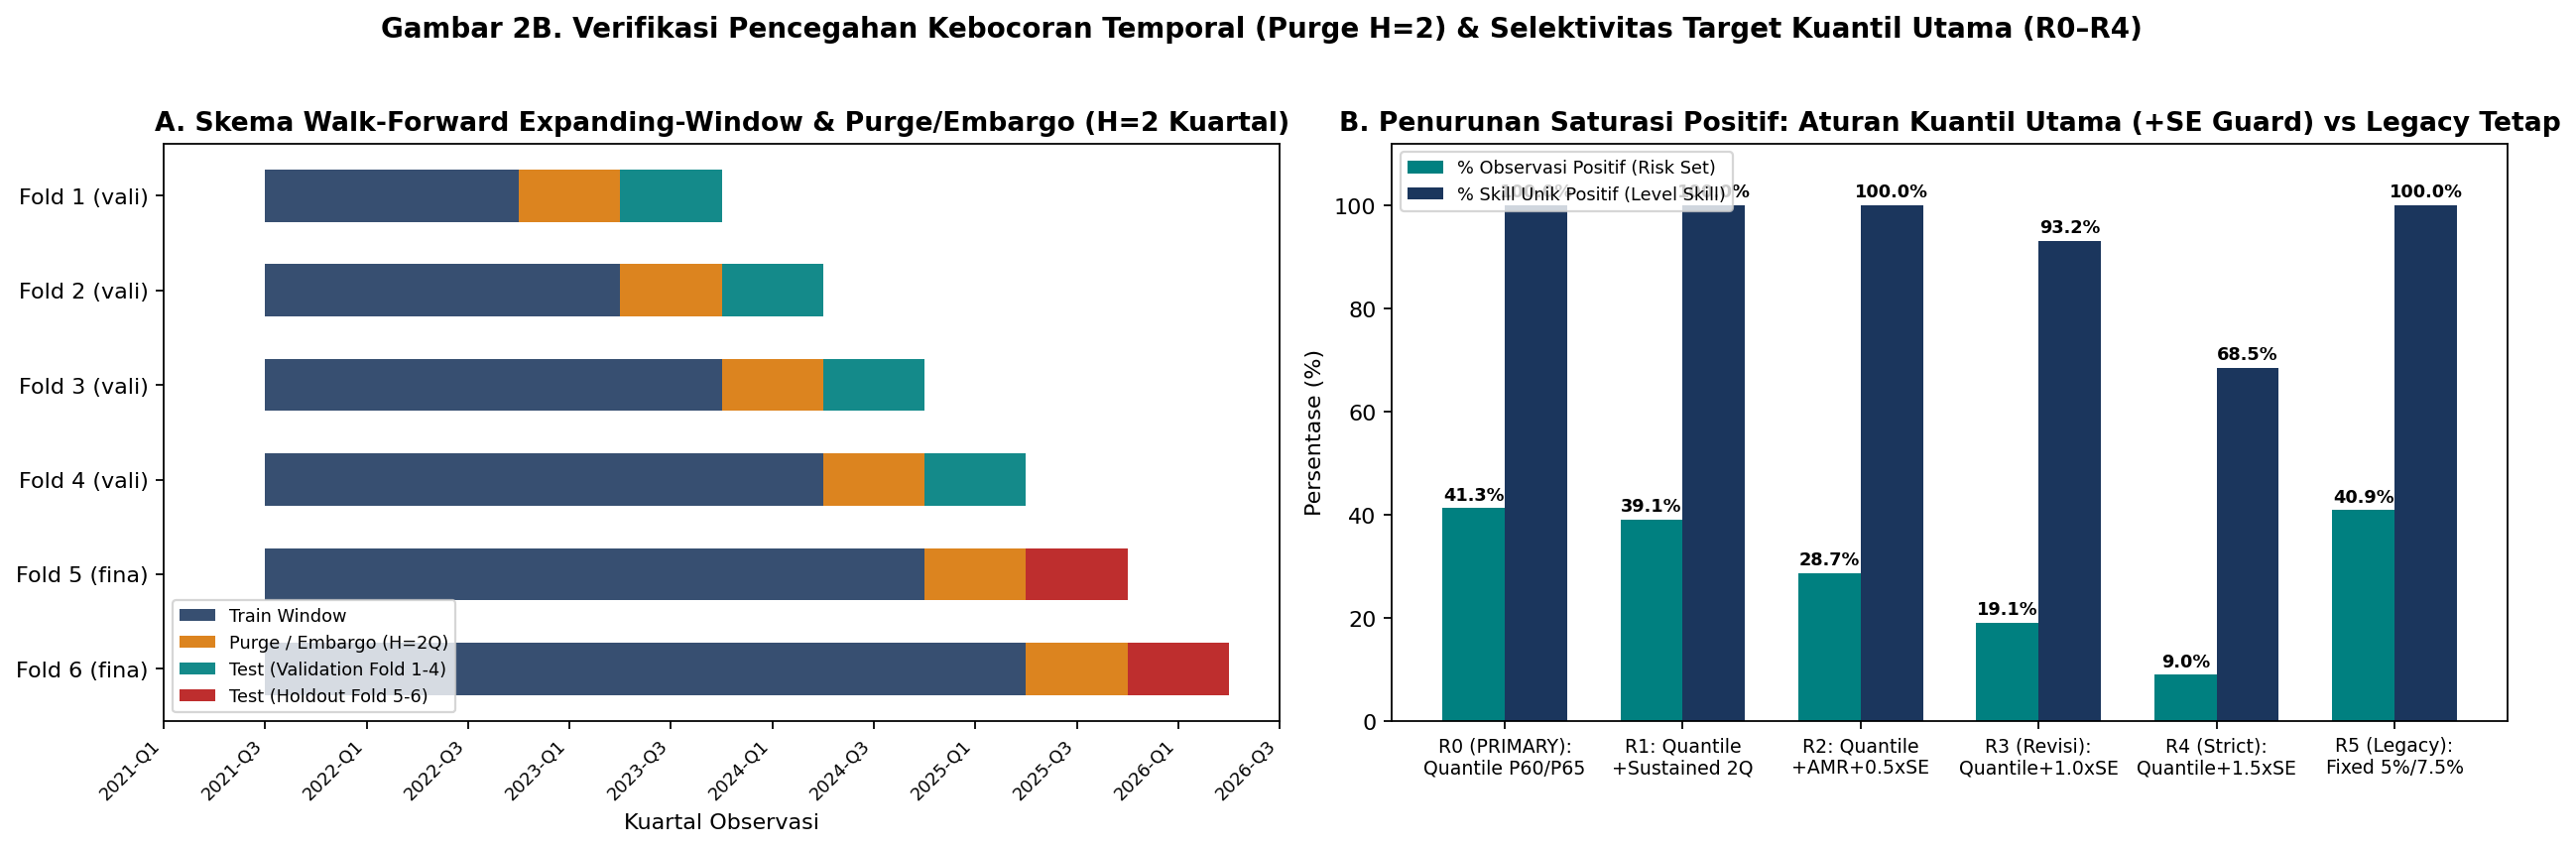

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
ax = axes[0]
q_order = sorted(labeled_panel_df["year_quarter"].unique())
q_to_idx = {q: i for i, q in enumerate(q_order)}

for _, r in folds_df.iterrows():
    fid = int(r["fold_id"])
    tr_parts = str(r["train_period"]).split("..")
    tr_start, tr_end = tr_parts[0].strip(), tr_parts[1].split("(")[0].strip()
    pu_qs = [x.strip() for x in str(r["purged_embargo_quarters"]).split(",")]
    te_qs = [x.strip() for x in str(r["test_period"]).split(",")]

    i_tr0, i_tr1 = q_to_idx[tr_start], q_to_idx[tr_end]
    i_pu0, i_pu1 = q_to_idx[pu_qs[0]], q_to_idx[pu_qs[-1]]
    i_te0, i_te1 = q_to_idx[te_qs[0]], q_to_idx[te_qs[-1]]

    ax.barh(fid, i_tr1 - i_tr0 + 1, left=i_tr0, height=0.55, color="#1B365D", alpha=0.88, label="Train Window" if fid == 1 else "")
    ax.barh(fid, i_pu1 - i_pu0 + 1, left=i_pu0, height=0.55, color="#D97706", alpha=0.90, label="Purge / Embargo (H=2Q)" if fid == 1 else "")
    te_col = "#008080" if r["fold_role"] == "validation" else "#B91C1C"
    te_lbl = "Test (Validation Fold 1-4)" if fid == 1 else ("Test (Holdout Fold 5-6)" if fid == 5 else "")
    ax.barh(fid, i_te1 - i_te0 + 1, left=i_te0, height=0.55, color=te_col, alpha=0.92, label=te_lbl)

ax.set_yticks(folds_df["fold_id"])
ax.set_yticklabels([f"Fold {r['fold_id']} ({r['fold_role'][:4]})" for _, r in folds_df.iterrows()])
ax.invert_yaxis()
ax.set_xticks(np.arange(0, len(q_order), 2))
ax.set_xticklabels(q_order[::2], rotation=45, ha="right", fontsize=8)
ax.set_title("A. Skema Walk-Forward Expanding-Window & Purge/Embargo (H=2 Kuartal)", fontweight="bold")
ax.set_xlabel("Kuartal Observasi")
ax.legend(loc="lower left", fontsize=8)

ax = axes[1]
short_regimes = [
    "R0 (PRIMARY):\nQuantile P60/P65",
    "R1: Quantile\n+Sustained 2Q",
    "R2: Quantile\n+AMR+0.5xSE",
    "R3 (Revisi):\nQuantile+1.0xSE",
    "R4 (Strict):\nQuantile+1.5xSE",
    "R5 (Legacy):\nFixed 5%/7.5%",
][:len(sensitivity_df)]
x_r = np.arange(len(sensitivity_df))
w_r = 0.35
b1 = ax.bar(x_r - w_r/2, sensitivity_df["positive_rate_pct"], width=w_r, color="#008080", label="% Observasi Positif (Risk Set)")
b2 = ax.bar(x_r + w_r/2, sensitivity_df["skill_level_positive_pct"], width=w_r, color="#1B365D", label="% Skill Unik Positif (Level Skill)")
for b in b1:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f"{b.get_height():.1f}%", ha="center", va="bottom", fontsize=8, fontweight="bold")
for b in b2:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f"{b.get_height():.1f}%", ha="center", va="bottom", fontsize=8, fontweight="bold")
ax.set_xticks(x_r)
ax.set_xticklabels(short_regimes, fontsize=8.5)
ax.set_ylim(0, 112)
ax.set_ylabel("Persentase (%)")
ax.set_title("B. Penurunan Saturasi Positif: Aturan Kuantil Utama (+SE Guard) vs Legacy Tetap", fontweight="bold")
ax.legend(loc="upper left", fontsize=8)

fig.suptitle("Gambar 2B. Verifikasi Pencegahan Kebocoran Temporal (Purge H=2) & Selektivitas Target Kuantil Utama (R0–R4)", fontsize=12.5, fontweight="bold", y=1.02)
fig.tight_layout()
cfg.figures_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(cfg.figures_dir / "fig2b_target_and_walk_forward_schedule.png", dpi=220, bbox_inches="tight")
plt.show()


## 4. Verifikasi Distribusi Kuantil Kausal pada Jendela Jangkar Fold 1 (`q_idx 2..6`)


In [4]:
def audit_causal_quantile_anchor(outcomes_df, cfg, q_levels=(0.25, 0.50, 0.60, 0.65, 0.70, 0.75, 0.80)):
    """
    Verifikasi bahwa ambang utama pada `cfg` diturunkan langsung dari kuantil jendela jangkar
    pra-evaluasi (q_idx 2..6, identik dengan training Fold 1) serta bandingkan distribusi gain
    1-kuartal (1Q) vs gain referensi Anti-Mean-Reversion (max(1Q, Roll4)).
    """
    H = cfg.horizon_quarters
    anchor_max_q = getattr(cfg, "anchor_max_quarter_idx", cfg.first_eval_quarter_idx - H - 1)
    d = outcomes_df[
        (outcomes_df["quarter_idx"] >= cfg.min_history_quarters)
        & (outcomes_df["quarter_idx"] <= anchor_max_q)
    ].copy()

    qs = list(q_levels)
    roll4_q = np.quantile(d["causal_roll4_share"], qs) * 100.0
    cmax_q = np.quantile(d["causal_cummax_share"], qs) * 100.0

    # Gunakan ambang kuantil utama yang telah diikat pada cfg (P60 roll4 & P65 cummax)
    cand = d[
        (d["causal_roll4_share"] <= cfg.max_baseline_share)
        & (d["causal_cummax_share"] <= cfg.max_career_cummax_share)
        & (d["has_complete_future_horizon"] == True)
    ].copy()

    abs_1q_cols = [f"future_abs_gain_1q_t_plus_{h}" if f"future_abs_gain_1q_t_plus_{h}" in cand.columns else f"future_abs_gain_t_plus_{h}" for h in range(1, H + 1)]
    rel_1q_cols = [f"future_rel_gain_1q_t_plus_{h}" if f"future_rel_gain_1q_t_plus_{h}" in cand.columns else f"future_rel_gain_t_plus_{h}" for h in range(1, H + 1)]
    abs_1q = cand[abs_1q_cols].max(axis=1)
    rel_1q = cand[rel_1q_cols].max(axis=1)

    abs_ref_cols = [f"future_abs_gain_ref_t_plus_{h}" if f"future_abs_gain_ref_t_plus_{h}" in cand.columns else f"future_abs_gain_t_plus_{h}" for h in range(1, H + 1)]
    rel_ref_cols = [f"future_rel_gain_ref_t_plus_{h}" if f"future_rel_gain_ref_t_plus_{h}" in cand.columns else f"future_rel_gain_t_plus_{h}" for h in range(1, H + 1)]
    abs_ref = cand[abs_ref_cols].max(axis=1)
    rel_ref = cand[rel_ref_cols].max(axis=1)

    table = pd.DataFrame({
        "Persentil": [f"P{int(q*100)}" for q in qs],
        "Roll4_PraEval (%)": np.round(roll4_q, 3),
        "CumMax_PraEval (%)": np.round(cmax_q, 3),
        "AbsGain_1Q_Legacy (pp)": np.round(np.quantile(abs_1q, qs) * 100.0, 3),
        "AbsGain_AntiMeanRev (pp)": np.round(np.quantile(abs_ref, qs) * 100.0, 3),
        "RelGain_1Q_Legacy (%)": np.round(np.quantile(rel_1q, qs) * 100.0, 2),
        "RelGain_AntiMeanRev (%)": np.round(np.quantile(rel_ref, qs) * 100.0, 2),
    })

    anchor_labeled = assign_emergence_labels_with_reasons(
        cand,
        max_baseline_share=cfg.max_baseline_share,
        max_career_cummax_share=cfg.max_career_cummax_share,
        min_future_job_count=cfg.min_future_job_count,
        min_future_abs_share_gain=cfg.min_future_abs_share_gain,
        min_future_rel_share_gain=cfg.min_future_rel_share_gain,
        min_history_quarters=cfg.min_history_quarters,
        use_anti_mean_reversion_baseline=cfg.use_anti_mean_reversion_baseline,
        min_se_guard_multiplier=cfg.min_se_guard_multiplier,
        require_sustained_horizon_mean=cfg.require_sustained_horizon_mean,
    )
    anchor_se10 = assign_emergence_labels_with_reasons(
        cand,
        max_baseline_share=cfg.max_baseline_share,
        max_career_cummax_share=cfg.max_career_cummax_share,
        min_future_job_count=cfg.min_future_job_count,
        min_future_abs_share_gain=cfg.min_future_abs_share_gain,
        min_future_rel_share_gain=cfg.min_future_rel_share_gain,
        min_history_quarters=cfg.min_history_quarters,
        use_anti_mean_reversion_baseline=True,
        min_se_guard_multiplier=1.0,
        require_sustained_horizon_mean=True,
    )
    pos_rate_primary = float((anchor_labeled["target_emerging"] == 1.0).mean() * 100.0)
    pos_rate_se10 = float((anchor_se10["target_emerging"] == 1.0).mean() * 100.0)
    pos_rate_legacy = float((anchor_labeled["target_emerging_legacy_fixed"] == 1.0).mean() * 100.0)

    print("=== VERIFIKASI ATURAN UTAMA KUANTIL KAUSAL PADA JENDELA JANGKAR FOLD 1 (q_idx 2..6) ===")
    print(f"Jendela jangkar: q_idx {cfg.min_history_quarters}..{anchor_max_q} (n={len(d)}), kandidat Risk Set Kuantil Utama n={len(cand)}")
    print(table.to_string(index=False))
    print("\n--- Parameter Konfigurasi Utama (cfg) yang Aktif (Diturunkan Langsung dari Kuantil Jangkar) ---")
    print(f"cfg.max_baseline_share        = P{int(cfg.risk_set_roll4_quantile*100)}(Roll4_PraEval)  = {cfg.max_baseline_share*100:.3f}% (menggantikan angka tetap 5,00%)")
    print(f"cfg.max_career_cummax_share   = P{int(cfg.risk_set_cummax_quantile*100)}(CumMax_PraEval) = {cfg.max_career_cummax_share*100:.3f}% (menggantikan angka tetap 7,50%)")
    print(f"cfg.min_future_abs_share_gain = {cfg.min_future_abs_share_gain*100:.3f} pp | cfg.min_future_rel_share_gain = {cfg.min_future_rel_share_gain*100:.2f}%")
    print(f"Tingkat positif jendela jangkar — Kuantil Kausal Utama (Optimal): {pos_rate_primary:.2f}% | Kuantil + Anti-Fluktuasi (>=1.0xSE): {pos_rate_se10:.2f}% | Legacy (Tetap 5%/7,5%): {pos_rate_legacy:.2f}%")
    return table

yazdanian_audit_df = audit_causal_quantile_anchor(outcomes_df, cfg)
yazdanian_audit_df.to_csv(cfg.audit_dir / "causal_quantile_anchor_audit.csv", index=False)


=== VERIFIKASI ATURAN UTAMA KUANTIL KAUSAL PADA JENDELA JANGKAR FOLD 1 (q_idx 2..6) ===
Jendela jangkar: q_idx 2..6 (n=565), kandidat Risk Set Kuantil Utama n=332
Persentil  Roll4_PraEval (%)  CumMax_PraEval (%)  AbsGain_1Q_Legacy (pp)  AbsGain_AntiMeanRev (pp)  RelGain_1Q_Legacy (%)  RelGain_AntiMeanRev (%)
      P25              1.314               2.066                  -0.246                    -0.571                 -15.01                   -25.62
      P50              3.512               5.071                   0.021                     0.000                   2.05                     0.00
      P60              4.737               6.838                   0.288                     0.000                  23.61                     0.00
      P65              5.510               7.938                   0.389                     0.075                  28.72                     4.39
      P70              6.615               8.884                   0.453                     0.175    

## 5. Analisis Sensitivitas Rezim Target terhadap Fluktuasi Permintaan (`Binomial SE Guard`)


In [5]:
def sensitivity_se_based_target(outcomes_df, cfg, k_se=(0.5, 1.0, 1.5, 2.0)):
    """
    Evaluasi bertahap bagaimana setiap lapisan proteksi anti-fluktuasi:
    (1) Aturan Kuantil Jangkar P60/P65,
    (2) Baseline Referensi Anti-Mean-Reversion max(skill_share_t, causal_roll4_share_t),
    (3) Konsistensi Rata-Rata 2 Kuartal (future_mean_share > baseline_ref), dan
    (4) Filter Galat Baku Sampling Binomial (abs_gain_ref >= k * SE)
    menurunkan derau positif dan menghilangkan saturasi positif pada tingkat skill.
    """
    eval_min_q = int(getattr(cfg, "first_eval_quarter_idx", 9))
    regimes = [
        ("T0 (Legacy): Ambang Tetap 5%/7,5% + Baseline 1Q (Tanpa Filter SE)", 0.0500, 0.0750, False, 0.0, False),
        ("T1 (PRIMARY OPTIMAL): Kuantil Kausal (P60=4.74%/P65=7.94%) + Surge Kuartal Individual", cfg.max_baseline_share, cfg.max_career_cummax_share, False, 0.0, False),
        ("T2: Kuantil Jangkar (P60/P65) + Baseline Anti-Mean-Reversion max(1Q, Roll4)", cfg.max_baseline_share, cfg.max_career_cummax_share, True, 0.0, False),
        ("T3: Kuantil Jangkar (P60/P65) + Anti-Mean-Reversion + Sustained 2Q Mean", cfg.max_baseline_share, cfg.max_career_cummax_share, True, 0.0, True),
    ]
    for k in k_se:
        lbl_tag = "Revisi Ketat 1.0xSE" if abs(k - 1.0) < 1e-6 else (f"Moderat {k:g}xSE" if k < 1.0 else f"Strict {k:g}xSE")
        regimes.append((
            f"T4_{k:g}xSE ({lbl_tag}): Kuantil (P60/P65) + Anti-Mean-Rev + Sustained 2Q + >={k:g}xSE",
            cfg.max_baseline_share, cfg.max_career_cummax_share, True, float(k), True,
        ))

    rows = []
    for name, max_b, max_c, use_amr, se_m, sust_2q in regimes:
        lab = assign_emergence_labels_with_reasons(
            outcomes_df,
            max_baseline_share=max_b,
            max_career_cummax_share=max_c,
            min_future_job_count=cfg.min_future_job_count,
            min_future_abs_share_gain=cfg.min_future_abs_share_gain,
            min_future_rel_share_gain=cfg.min_future_rel_share_gain,
            min_history_quarters=cfg.min_history_quarters,
            restrict_to_risk_set=True,
            use_anti_mean_reversion_baseline=use_amr,
            min_se_guard_multiplier=se_m,
            require_sustained_horizon_mean=sust_2q,
        )
        valid_all = lab[lab["target_emerging"].notna()]
        valid_oos = valid_all[valid_all["quarter_idx"] >= eval_min_q]
        if len(valid_oos) == 0:
            valid_oos = valid_all

        n_risk = len(valid_all)
        n_pos = int((valid_all["target_emerging"] == 1.0).sum())
        tot_sk_all = int(valid_all["skill"].nunique())
        pos_sk_all = int(valid_all.loc[valid_all["target_emerging"] == 1.0, "skill"].nunique())

        tot_sk_oos = int(valid_oos["skill"].nunique())
        pos_sk_oos = int(valid_oos.loc[valid_oos["target_emerging"] == 1.0, "skill"].nunique())
        neg_sk_oos = tot_sk_oos - pos_sk_oos

        rows.append({
            "definisi_target": name,
            "n_risk_set": n_risk,
            "n_positif": n_pos,
            "tingkat_positif_%": round(n_pos / max(n_risk, 1) * 100.0, 2),
            "skill_unik_positif": pos_sk_all,
            "skill_unik_negatif_murni": tot_sk_all - pos_sk_all,
            "skill_oos_total": tot_sk_oos,
            "skill_oos_positif": pos_sk_oos,
            "skill_oos_negatif_murni": neg_sk_oos,
            "saturasi_skill_oos_%": round(pos_sk_oos / max(tot_sk_oos, 1) * 100.0, 2),
        })

    out = pd.DataFrame(rows)
    print("=== DEKOMPOSISI TARGET ANTI-FLUKTUASI & PENURUNAN SATURASI POSITIF TINGKAT SKILL ===")
    print(out.to_string(index=False))
    return out

def build_se_filtered_labeled_panel(
    outcomes_df: pd.DataFrame,
    cfg: Any,
    k_se: float = 1.0,
    use_roll4_baseline: bool = True,
    require_sustained_2q: bool = True,
) -> pd.DataFrame:
    """
    Bentuk panel berlabel menggunakan aturan Kuantil Utama pada `cfg` dengan pengali SE `k_se`
    dan opsi baseline Anti-Mean-Reversion (`use_roll4_baseline=True`).
    """
    return assign_emergence_labels_with_reasons(
        outcomes_df,
        max_baseline_share=cfg.max_baseline_share,
        max_career_cummax_share=cfg.max_career_cummax_share,
        min_future_job_count=cfg.min_future_job_count,
        min_future_abs_share_gain=cfg.min_future_abs_share_gain,
        min_future_rel_share_gain=cfg.min_future_rel_share_gain,
        min_history_quarters=cfg.min_history_quarters,
        restrict_to_risk_set=True,
        use_anti_mean_reversion_baseline=use_roll4_baseline,
        min_se_guard_multiplier=k_se,
        require_sustained_horizon_mean=require_sustained_2q,
    )

se_sensitivity_df = sensitivity_se_based_target(outcomes_df, cfg)
se_sensitivity_df.to_csv(cfg.audit_dir / "se_based_target_sensitivity.csv", index=False)

demo_state_dir = cfg.outputs_dir / "demo_state"
demo_state_dir.mkdir(parents=True, exist_ok=True)
with open(demo_state_dir / "stage03_state.pkl", "wb") as _f:
    pickle.dump({
        "cfg": cfg,
        "feat_df": feat_df,
        "outcomes_df": outcomes_df,
        "quantile_anchor_info": quantile_anchor_info,
        "labeled_panel_df": labeled_panel_df,
        "funnel_df": funnel_df,
        "sensitivity_df": sensitivity_df,
        "folds": folds,
        "folds_df": folds_df,
        "yazdanian_audit_df": yazdanian_audit_df,
        "se_sensitivity_df": se_sensitivity_df,
        "audit_tables": globals().get("audit_tables", {}),
    }, _f)


=== DEKOMPOSISI TARGET ANTI-FLUKTUASI & PENURUNAN SATURASI POSITIF TINGKAT SKILL ===
                                                                         definisi_target  n_risk_set  n_positif  tingkat_positif_%  skill_unik_positif  skill_unik_negatif_murni  skill_oos_total  skill_oos_positif  skill_oos_negatif_murni  saturasi_skill_oos_%
                       T0 (Legacy): Ambang Tetap 5%/7,5% + Baseline 1Q (Tanpa Filter SE)        1270        519              40.87                  72                         0               69                 68                        1                 98.55
   T1 (PRIMARY OPTIMAL): Kuantil Kausal (P60=4.74%/P65=7.94%) + Surge Kuartal Individual        1270        524              41.26                  73                         0               71                 69                        2                 97.18
             T2: Kuantil Jangkar (P60/P65) + Baseline Anti-Mean-Reversion max(1Q, Roll4)        1270        390              30.71     